In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import glob
from pathlib import Path
import plotly.express as px
import seaborn as sns
import emoji
import re

from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer


## Read csv files

In [2]:
cwd = Path.cwd()
print(cwd)

/Users/emilyjiang/Documents/GitHub/shorts-data


In [3]:
channels_df = pd.read_csv(cwd/'data'/'channels.csv')
channels_df.head()

,channel_id,first_seen_at,channel_title,channel_created_at,total_channel_views,subscriber_count,total_channel_videos
0,UCJgZiklqrfvvfCDO3QhF1Hg,2026-10-12T15:37:58.074627+00:00,kk shorts video,2021-03-26T15:35:22.996177Z,5110271644,3780000,1253
1,UC3NlznSlTlfiNpUhfdJlTiw,2026-10-12T15:37:58.074627+00:00,NLF SoHeL VloG,2024-10-17T06:22:42.920227Z,10787169127,3480000,4666
2,UC5k3V8mUODYybpi2O4O6Atw,2026-10-12T15:37:58.074627+00:00,MegaMarkGames,2013-08-02T01:42:13Z,9939467,432000,3627
3,UC1PlB1jO4-sfrSdqRrvCllA,2026-10-12T15:37:58.074627+00:00,Ram Ji,2026-06-03T05:24:55.322944Z,91083513,95400,269
4,UCTkeM1GjDqx3Bw0q-WVjTNQ,2026-10-12T15:37:58.074627+00:00,小山翔平,2023-02-17T07:46:26.368324Z,84502329,78500,3106


In [4]:
videos_df = pd.read_csv(cwd/'data'/'videos.csv')
videos_df.head()

,video_id,first_seen_at,published_at,channel_id,channel_title,title,description,duration,duration_seconds,tags
0,L5eQJKakz5U,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:15:22Z,UC0cx38VIfmVZva-rYnMmevQ,Amandinha,Abrindo Comprinhas da Shopika 6 #shorts,💜APOIE A AMANDINHA E SE TORNE MEMBRO DO CANAL!...,PT3M,180,[]
1,PdrruRfk_wM,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:10:15Z,UCTHuHxhCBITUuP_AchYSstA,RAXON,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts,Who Cleans Spider-Man’s Webs? 🤣😂 | #shorts\n\n...,PT48S,48,[]
2,LAhmgGBiESw,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:08:05Z,UC8_NGoazMiGbRPUTQ52_NdQ,Jagiya the fun,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,Jagiya ke kurkure aur chota bhai🥲🔥| Indian fam...,PT32S,32,[]
3,8qJ5k-vbO3E,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:05:44Z,UConRqB3CsY3dAHvVDVsRC4g,Mr_Vlogger,hair loss problem #shorts #minivlog #vlogs,NaN,PT24S,24,[]
4,VP3sxzlp4P0,2026-10-12T15:37:58.074627+00:00,2026-10-12T15:00:07Z,UCa9nE9GRjSOXFL1alnROYEA,Rinconcito Animado,¿Dónde se perdió Bob Esponja? 😱 #viral #shorts,🍍😂 ¡Bob Esponja se perdió intentando encontrar...,PT1M2S,62,[]


In [5]:
countries_df = pd.read_csv(cwd/'data'/'channel_countries.csv')
countries_df.head()

,channel_id,channel_country,country_checked_at
0,UC-MBfVUWu59urBn7WdXGJAA,US,2026-10-16T16:53:21.765904+00:00
1,UC-NIoAJGtb-Ze0KSqR77wuw,BR,2026-10-16T16:53:21.765904+00:00
2,UC-Pjg6st-ragcrS-h51mo0w,NaN,2026-10-16T16:53:21.765904+00:00
3,UC-NHROR0npP1l_6WVse2pxA,IN,2026-10-16T16:53:21.765904+00:00
4,UC-1vgrqMJMNw9E0aIZlU4zQ,IN,2026-10-16T16:53:21.765904+00:00


### Process observation data

In [6]:
observation_files = glob.glob(str(cwd/'data'/'observations'/'*.csv'))

In [7]:
# concat observations into one data frame
observation_df = pd.concat(
    [pd.read_csv(file) for file in observation_files],
    ignore_index=True
)

# sort by video id and observation data
observation_df = observation_df.sort_values(["video_id", "observed_at"])

In [8]:
observation_df.head()

,video_id,observed_at,age_hours,view_count,like_count,comment_count
667845,--S4wKspUZU,2026-10-16T05:53:39.748227+00:00,1.022,3647.0,41.0,9.0
822060,--S4wKspUZU,2026-10-16T06:53:34.896162+00:00,2.021,4641.0,62.0,14.0
956427,--S4wKspUZU,2026-10-16T07:53:31.797928+00:00,3.020,6181.0,76.0,15.0
44762,--S4wKspUZU,2026-10-16T08:53:34.646128+00:00,4.021,7788.0,89.0,18.0
703243,--S4wKspUZU,2026-10-16T09:53:40.665003+00:00,5.023,9396.0,103.0,20.0


In [9]:
observation_df

,video_id,observed_at,age_hours,view_count,like_count,comment_count
667845,--S4wKspUZU,2026-10-16T05:53:39.748227+00:00,1.022,3647.0,41.0,9.0
822060,--S4wKspUZU,2026-10-16T06:53:34.896162+00:00,2.021,4641.0,62.0,14.0
956427,--S4wKspUZU,2026-10-16T07:53:31.797928+00:00,3.020,6181.0,76.0,15.0
44762,--S4wKspUZU,2026-10-16T08:53:34.646128+00:00,4.021,7788.0,89.0,18.0
703243,--S4wKspUZU,2026-10-16T09:53:40.665003+00:00,5.023,9396.0,103.0,20.0
...,...,...,...,...,...,...
176881,zzby5PLoQTI,2026-10-15T16:53:25.697784+00:00,75.885,1090830.0,29120.0,135.0
733056,zzby5PLoQTI,2026-10-15T17:53:27.611454+00:00,76.885,1107786.0,29509.0,136.0
87,zzby5PLoQTI,2026-10-15T18:53:22.502848+00:00,77.884,1165355.0,29805.0,137.0
544781,zzby5PLoQTI,2026-10-15T19:53:23.931139+00:00,78.884,1182118.0,30065.0,138.0


In [10]:
observation_df.groupby("observed_at")["video_id"].nunique()

observed_at
2026-10-12T15:37:59.683152+00:00    50
2026-10-12T15:37:59.850397+00:00    46
2026-10-12T18:14:30.357946+00:00    50
2026-10-12T18:14:30.522698+00:00    50
2026-10-12T18:14:30.671792+00:00    50
                                    ..
2026-10-22T05:53:39.034525+00:00    50
2026-10-22T05:53:39.172200+00:00    50
2026-10-22T05:53:39.278682+00:00    50
2026-10-22T05:53:39.387635+00:00    50
2026-10-22T05:53:39.493735+00:00    46
Name: video_id, Length: 20785, dtype: int64

In [11]:
# add column observation number
observation_df["n_observation"] = observation_df.groupby("video_id").cumcount() + 1

## Data Analysis

### Create new data frame for analysis
Filters videos to only U.S. channels and includes like and view counts at different times

In [12]:
# 1. Get channel IDs for US channels
us_channel_ids = countries_df.loc[
    countries_df["channel_country"] == "US", "channel_id"
].unique()

# 2. Filter channels and videos to US channels
us_channels_df = channels_df[
    channels_df["channel_id"].isin(us_channel_ids)
].copy()

us_videos_df = videos_df[
    videos_df["channel_id"].isin(us_channel_ids)
].copy()

# 3. Get observations at 1, 6, and 24 hours
target_hours = [1, 6, 24]

selected_df = observation_df[
    observation_df["n_observation"].isin(target_hours)
].copy()

# Pivot view counts
views_df = selected_df.pivot_table(
    index="video_id",
    columns="n_observation",
    values="view_count",
    aggfunc="last"
)

views_df.columns = [
    f"views_{int(hour)}hr" for hour in views_df.columns
]

# Pivot like counts
likes_df = selected_df.pivot_table(
    index="video_id",
    columns="n_observation",
    values="like_count",
    aggfunc="last"
)

likes_df.columns = [
    f"likes_{int(hour)}hr" for hour in likes_df.columns
]

# Combine view and like counts
metrics_df = pd.concat(
    [views_df, likes_df], axis=1
).reset_index()

# 4. Select video metadata
video_info = us_videos_df[
    ["video_id", "title", "channel_id", "channel_title", "description", "tags", "duration"]
].drop_duplicates(subset="video_id")

# 5. Select channel subscriber counts
channel_info = us_channels_df[
    ["channel_id", "subscriber_count"]
].drop_duplicates(subset="channel_id")

# 6. Merge the data
analysis_df = (
    video_info
    .merge(channel_info, on="channel_id", how="left")
    .merge(metrics_df, on="video_id", how="left")
)

# 7. Keep requested columns
analysis_df = analysis_df[
    [
        "title",
        "channel_title",
        "subscriber_count",
        "duration",
        "description",
        "tags",
        "views_1hr",
        "likes_1hr",
        "views_6hr",
        "likes_6hr",
        "views_24hr",
        "likes_24hr",
    ]
]

analysis_df.head()


,title,channel_title,subscriber_count,duration,description,tags,views_1hr,likes_1hr,views_6hr,likes_6hr,views_24hr,likes_24hr
0,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,Hercai Español,753000,PT1M47S,"Reyyan es la nieta de la familia Sadoglu, una ...","[""atv series"", ""Ver Ak\u0131n Ak\u0131n\u00f6z...",227.0,9.0,5700.0,364.0,17513.0,763.0
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,PT49S,NaN,[],57327.0,1175.0,324538.0,4667.0,534648.0,7368.0
2,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",New England Patriots,420000,PT29S,NaN,[],4480.0,350.0,15366.0,655.0,21755.0,806.0
3,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",Bears Now by Chat Sports,174000,PT56S,NaN,[],4786.0,511.0,42406.0,1450.0,53081.0,1676.0
4,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,FurtherEdit,740000,PT1M58S,🎬 Original Edit — Crafted with Precision\n\nCu...,"[""#shorts"", ""#edit"", ""#movie""]",11167.0,932.0,33607.0,1816.0,73092.0,3232.0


### Add different virality metrics to analysis data frame

In [13]:
# Absolute growth
analysis_df["views_gained_24hr"] = (
    analysis_df["views_24hr"] - analysis_df["views_1hr"]
)

# Average views gained per hour from hour 1 to hour 24
analysis_df["avg_views_per_hour"] = (
    analysis_df["views_gained_24hr"] / 23
)

# Views relative to channel subscriber count
analysis_df["views_per_subscriber"] = (
    analysis_df["views_24hr"]
    / analysis_df["subscriber_count"].replace(0, np.nan)
)

# Relative growth from hour 1 to hour 24
analysis_df["relative_growth"] = (
    analysis_df["views_gained_24hr"]
    / analysis_df["views_1hr"].replace(0, np.nan)
)

# Like rate at 24 hours
analysis_df["like_rate_24hr"] = (
    analysis_df["likes_24hr"]
    / analysis_df["views_24hr"].replace(0, np.nan)
)

# Growth during the 1-to-6-hour and 6-to-24-hour periods
analysis_df["views_gained_1_to_6hr"] = (
    analysis_df["views_6hr"] - analysis_df["views_1hr"]
)

analysis_df["views_gained_6_to_24hr"] = (
    analysis_df["views_24hr"] - analysis_df["views_6hr"]
)

# Average hourly growth during each period
analysis_df["rate_1_to_6hr"] = (
    analysis_df["views_gained_1_to_6hr"] / 5
)

analysis_df["rate_6_to_24hr"] = (
    analysis_df["views_gained_6_to_24hr"] / 18
)

# Change in average hourly growth rate
analysis_df["growth_acceleration"] = (
    analysis_df["rate_6_to_24hr"]
    - analysis_df["rate_1_to_6hr"]
)

### Add title features

In [14]:
# add title features to the dataset

# Handle missing titles
titles = analysis_df["title"].fillna("").astype(str)

# Length and structure
analysis_df["title_length"] = titles.str.len()
analysis_df["word_count"] = titles.str.split().str.len()

# Capitalization
analysis_df["uppercase_count"] = titles.apply(
    lambda x: sum(c.isupper() for c in x)
)

analysis_df["uppercase_ratio"] = titles.apply(
    lambda x: (
        sum(c.isupper() for c in x if c.isalpha())
        / sum(c.isalpha() for c in x)
        if any(c.isalpha() for c in x)
        else 0
    )
)

analysis_df["is_all_caps"] = titles.apply(
    lambda x: (
        any(c.isalpha() for c in x)
        and all(not c.isalpha() or c.isupper() for c in x)
    )
)

# Punctuation
analysis_df["exclamation_count"] = titles.str.count("!")
analysis_df["question_count"] = titles.str.count(r"\?")
analysis_df["has_exclamation"] = titles.str.contains("!", regex=False)
analysis_df["has_question"] = titles.str.contains("?", regex=False)

analysis_df["has_ellipsis"] = titles.str.contains(
    r"\.\.\.|…", regex=True
)

analysis_df["repeated_punctuation"] = titles.str.contains(
    r"[!?]{2,}", regex=True
)

# Emojis
analysis_df["emoji_count"] = titles.apply(emoji.emoji_count)
analysis_df["has_emoji"] = analysis_df["emoji_count"] > 0

# Hashtags
analysis_df["has_hashtag"] = titles.str.contains("#", regex=False)
analysis_df["hashtag_count"] = titles.apply(
    lambda x: len(re.findall(r"(?<!\w)#\w+", x))
)

# Numbers
analysis_df["has_number"] = titles.str.contains(r"\d", regex=True)
analysis_df["number_count"] = titles.str.count(r"\d")

# Character encoding
analysis_df["is_ascii"] = titles.str.isascii()

analysis_df.head()

,title,channel_title,subscriber_count,duration,description,tags,views_1hr,likes_1hr,views_6hr,likes_6hr,...,has_question,has_ellipsis,repeated_punctuation,emoji_count,has_emoji,has_hashtag,hashtag_count,has_number,number_count,is_ascii
0,¡Reyyan abofeteó a Yaren!😲| Hercai #shorts,Hercai Español,753000,PT1M47S,"Reyyan es la nieta de la familia Sadoglu, una ...","[""atv series"", ""Ver Ak\u0131n Ak\u0131n\u00f6z...",227.0,9.0,5700.0,364.0,...,False,False,False,1,True,True,1,False,0,False
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,PT49S,NaN,[],57327.0,1175.0,324538.0,4667.0,...,False,False,False,0,False,True,4,False,0,True
2,"DeMario ""Pop had 2 tuds"" Douglas 👌 #patriots #...",New England Patriots,420000,PT29S,NaN,[],4480.0,350.0,15366.0,655.0,...,False,False,False,1,True,True,3,True,1,False
3,"Ian Rapoport: ""All Signs Point"" Toward Caleb W...",Bears Now by Chat Sports,174000,PT56S,NaN,[],4786.0,511.0,42406.0,1450.0,...,False,False,False,0,False,True,3,False,0,True
4,Name: Grey’s Anatomy | She Chose Freedom.🎬🎬 #m...,FurtherEdit,740000,PT1M58S,🎬 Original Edit — Crafted with Precision\n\nCu...,"[""#shorts"", ""#edit"", ""#movie""]",11167.0,932.0,33607.0,1816.0,...,False,False,False,2,True,True,3,False,0,False


### Use outliers from avg views per hour to identify viral videos

In [15]:
# identify outliers based on avg views per hour

# Calculate average views per hour
analysis_df["avg_views_per_hour"] = (
    analysis_df["views_24hr"] - analysis_df["views_1hr"]
) / 23

valid_df = analysis_df.dropna(
    subset=["avg_views_per_hour"]
).copy()

# IQR outlier threshold
Q1 = valid_df["avg_views_per_hour"].quantile(0.25)
Q3 = valid_df["avg_views_per_hour"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

valid_df["viral"] = (
    valid_df["avg_views_per_hour"] > upper_bound
)

viral_df = valid_df[valid_df["viral"]].copy()
non_viral_df = valid_df[~valid_df["viral"]].copy()

print(f"Outlier threshold: {upper_bound:,.2f} views/hour")
print(f"Viral videos: {len(viral_df)}")
print(f"Non-viral videos: {len(non_viral_df)}")


Outlier threshold: 16,505.93 views/hour
Viral videos: 187
Non-viral videos: 1306


In [66]:
viral_df.head()

,title,channel_title,subscriber_count,duration,description,tags,views_1hr,likes_1hr,views_6hr,likes_6hr,...,has_ellipsis,repeated_punctuation,emoji_count,has_emoji,has_hashtag,hashtag_count,has_number,number_count,is_ascii,viral
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,PT49S,NaN,[],57327.0,1175.0,324538.0,4667.0,...,False,False,0,0,1,4,0,0,True,True
5,Who Did She Draw? 🥕✏️ #shorts,GOLDCRAFT STUDIOS,11500000,PT6S,Can you guess who she drew? 🥕✏️ Watch until th...,"[""#MINECRAFT #TRENDING #KIDS #FYP #POPULAR""]",215026.0,6306.0,1138262.0,22932.0,...,False,False,2,1,1,1,0,0,False,True
6,EPISODE 2: Backbencher vs Topper of class CLAS...,Myst Editz,134000,PT22S,Solve: 41 x 41 = ? 🧐\n\ncredit: @Mathx_Study \...,"[""math shorts"", ""math tricks"", ""math hacks"", ""...",18683.0,NaN,141864.0,NaN,...,False,False,3,1,1,1,1,1,False,True
8,💗 I Couldn't Save My Sister 🏡 Roblox Story #ro...,Luca Fairy,1920000,PT2M14S,💗 I Couldn't Save My Sister 🏡 Roblox Story #ro...,"[""roblox gay story"", ""reacting to roblox story...",39096.0,2196.0,246674.0,8195.0,...,False,False,2,1,1,2,0,0,False,True
10,Taylor Momsen destroys a mic with her voice! #...,Rick Beato,5870000,PT43S,NaN,[],19469.0,877.0,162720.0,4676.0,...,False,False,0,0,1,3,0,0,False,True


### Correlation matrices comparing viral and non-viral videos

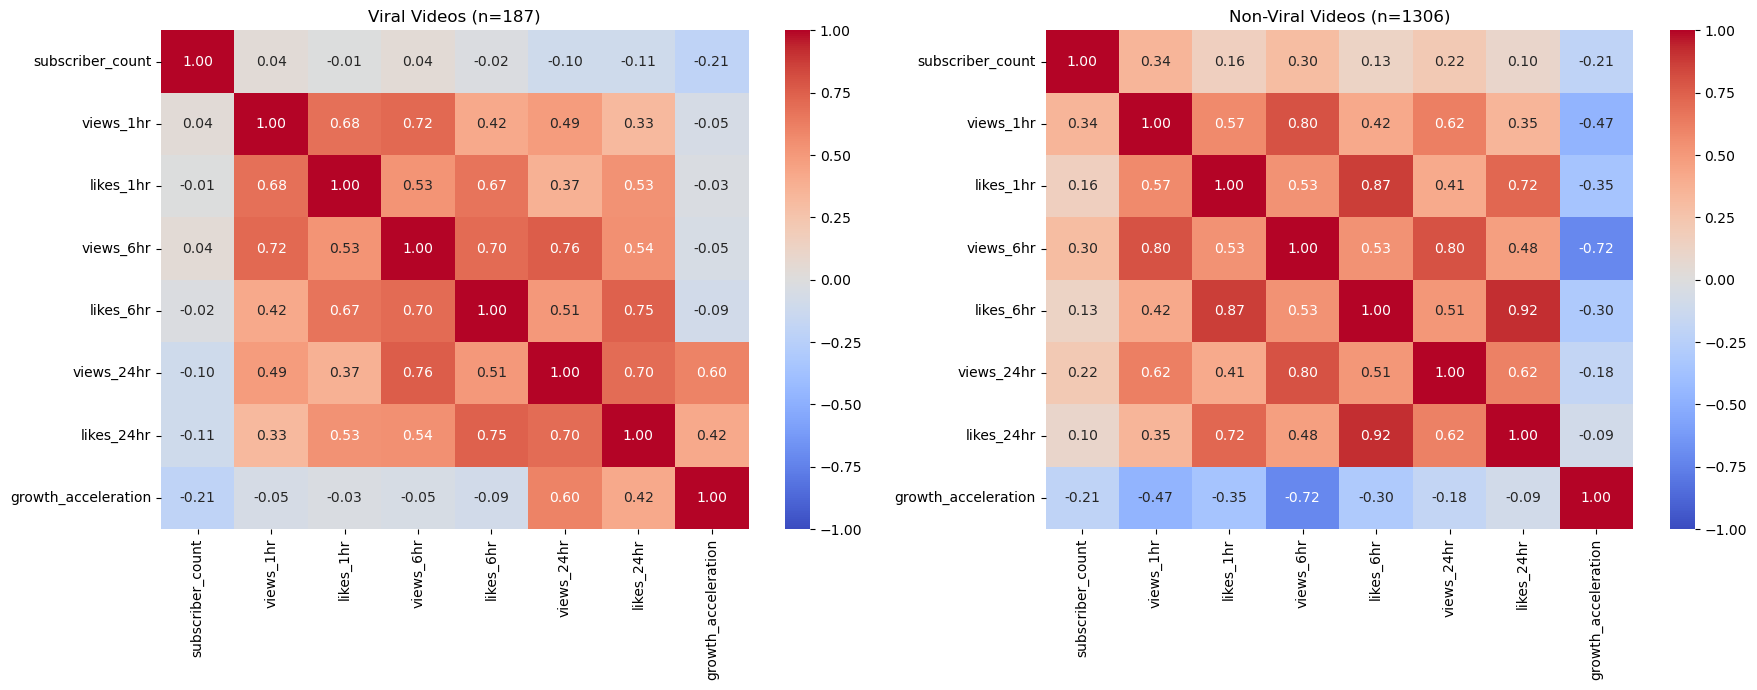

In [65]:
# create correlation matrices
features = [
    "subscriber_count",
    "views_1hr",
    "likes_1hr",
    "views_6hr",
    "likes_6hr",
    "views_24hr",
    "likes_24hr",
    "rate_1_to_6_hr",
    "growth_acceleration"
]

# Keep only columns present in the dataframe
features = [
    col for col in features
    if col in valid_df.columns
]

viral_corr = viral_df[features].corr(method="pearson")
non_viral_corr = non_viral_df[features].corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(
    viral_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title(f"Viral Videos (n={len(viral_df)})")

sns.heatmap(
    non_viral_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title(f"Non-Viral Videos (n={len(non_viral_df)})")

plt.tight_layout()
plt.show()


In [59]:
title_features = [
    "title_length",
    "word_count",
    "uppercase_ratio",
    "is_all_caps",
    "has_exclamation",
    "has_question",
    "has_emoji",
    "emoji_count",
    "has_hashtag",
    "hashtag_count",
    "has_number"
]

performance_features = [
    "views_1hr",
    "views_6hr",
    "views_24hr",
    "likes_1hr",
    "likes_6hr",
    "likes_24hr",
    "views_per_subscriber",
    "relative_growth",
    "like_rate",
    "growth_acceleration"
]

# Keep features that exist in your data
title_features = [
    c for c in title_features
    if c in analysis_df.columns
]
performance_features = [
    c for c in performance_features
    if c in analysis_df.columns
]

# Convert boolean features to numeric
for df in [viral_df, non_viral_df]:
    for col in title_features:
        if col in df.columns and df[col].dtype == bool:
            df[col] = df[col].astype(int)

# Correlation matrices: title features vs. performance
viral_corr = viral_df[title_features + performance_features].corr(
    method="spearman"
).loc[title_features, performance_features]

non_viral_corr = non_viral_df[
    title_features + performance_features
].corr(method="spearman").loc[
    title_features, performance_features
]

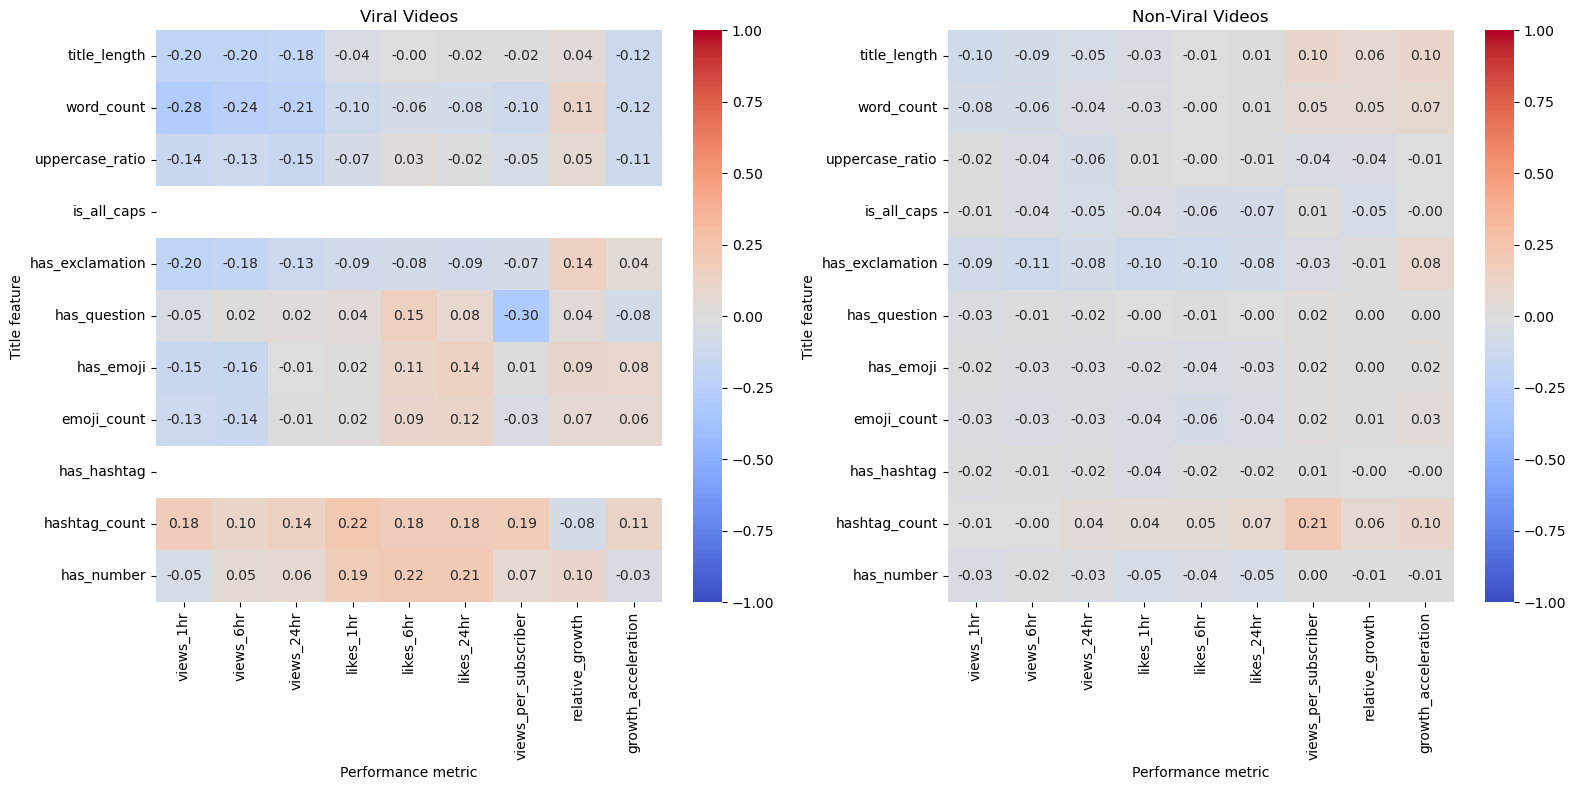

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.heatmap(
    viral_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[0]
)
axes[0].set_title("Viral Videos")
axes[0].set_xlabel("Performance metric")
axes[0].set_ylabel("Title feature")

sns.heatmap(
    non_viral_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    ax=axes[1]
)
axes[1].set_title("Non-Viral Videos")
axes[1].set_xlabel("Performance metric")
axes[1].set_ylabel("Title feature")

plt.tight_layout()
plt.show()

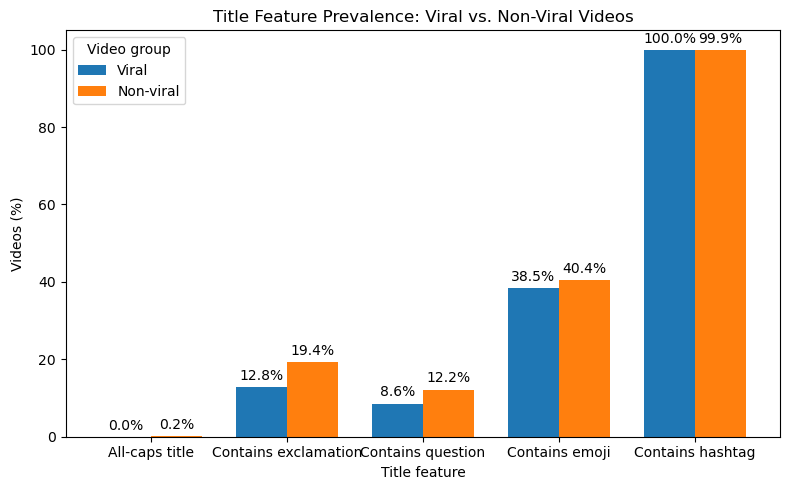

In [76]:
features = {
    "All-caps title": "is_all_caps",
    "Contains exclamation": "has_exclamation",
    "Contains question": "has_question",
    "Contains emoji": "has_emoji",
    "Contains hashtag": "has_hashtag",
}

ratios = pd.DataFrame({
    "Viral": {
        label: viral_df[col].mean()
        for label, col in features.items()
    },
    "Non-viral": {
        label: non_viral_df[col].mean()
        for label, col in features.items()
    }
})

ax = (ratios * 100).plot(
    kind="bar",
    figsize=(8, 5),
    width=0.75
)

ax.set_ylabel("Videos (%)")
ax.set_xlabel("Title feature")
ax.set_title("Title Feature Prevalence: Viral vs. Non-Viral Videos")
ax.set_xticklabels(ratios.index, rotation=0)
ax.legend(title="Video group")

# Label bars with percentages
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

In [73]:
viral_df[viral_df["has_hashtag"] == 1]  # every viral video has hashtags in title

,title,channel_title,subscriber_count,duration,description,tags,views_1hr,likes_1hr,views_6hr,likes_6hr,...,has_ellipsis,repeated_punctuation,emoji_count,has_emoji,has_hashtag,hashtag_count,has_number,number_count,is_ascii,viral
1,#Spider-Man #Gwen #Shorts #Spider-Gwen,正义格温,141000,PT49S,NaN,[],57327.0,1175.0,324538.0,4667.0,...,False,False,0,0,1,4,0,0,True,True
5,Who Did She Draw? 🥕✏️ #shorts,GOLDCRAFT STUDIOS,11500000,PT6S,Can you guess who she drew? 🥕✏️ Watch until th...,"[""#MINECRAFT #TRENDING #KIDS #FYP #POPULAR""]",215026.0,6306.0,1138262.0,22932.0,...,False,False,2,1,1,1,0,0,False,True
6,EPISODE 2: Backbencher vs Topper of class CLAS...,Myst Editz,134000,PT22S,Solve: 41 x 41 = ? 🧐\n\ncredit: @Mathx_Study \...,"[""math shorts"", ""math tricks"", ""math hacks"", ""...",18683.0,NaN,141864.0,NaN,...,False,False,3,1,1,1,1,1,False,True
8,💗 I Couldn't Save My Sister 🏡 Roblox Story #ro...,Luca Fairy,1920000,PT2M14S,💗 I Couldn't Save My Sister 🏡 Roblox Story #ro...,"[""roblox gay story"", ""reacting to roblox story...",39096.0,2196.0,246674.0,8195.0,...,False,False,2,1,1,2,0,0,False,True
10,Taylor Momsen destroys a mic with her voice! #...,Rick Beato,5870000,PT43S,NaN,[],19469.0,877.0,162720.0,4676.0,...,False,False,0,0,1,3,0,0,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1420,I Just Iced Out All 50 States With Diamonds #t...,TraxNYC Diamond Jewelry,4930000,PT36S,We took all 50 states and hand set each of the...,"[""diamond"", ""gold"", ""iced out"", ""iced out pend...",3031.0,253.0,138560.0,8815.0,...,False,False,0,0,1,3,1,2,True,True
1435,Best lava moments #shorts #memes,VITMI,7700000,PT25S,NaN,[],49615.0,735.0,348024.0,4230.0,...,False,False,0,0,1,2,0,0,True,True
1437,A Black MYSTERY Box Falls From The SKY... #sho...,Noobified,436000,PT2M53S,NaN,[],58090.0,2540.0,793435.0,20632.0,...,True,False,0,0,1,3,0,0,True,True
1459,Chloe caught trying to steal Mj Ps5 #shorts,FunnyMike,14500000,PT16S,NaN,[],35904.0,633.0,239362.0,2877.0,...,False,False,0,0,1,1,1,1,True,True


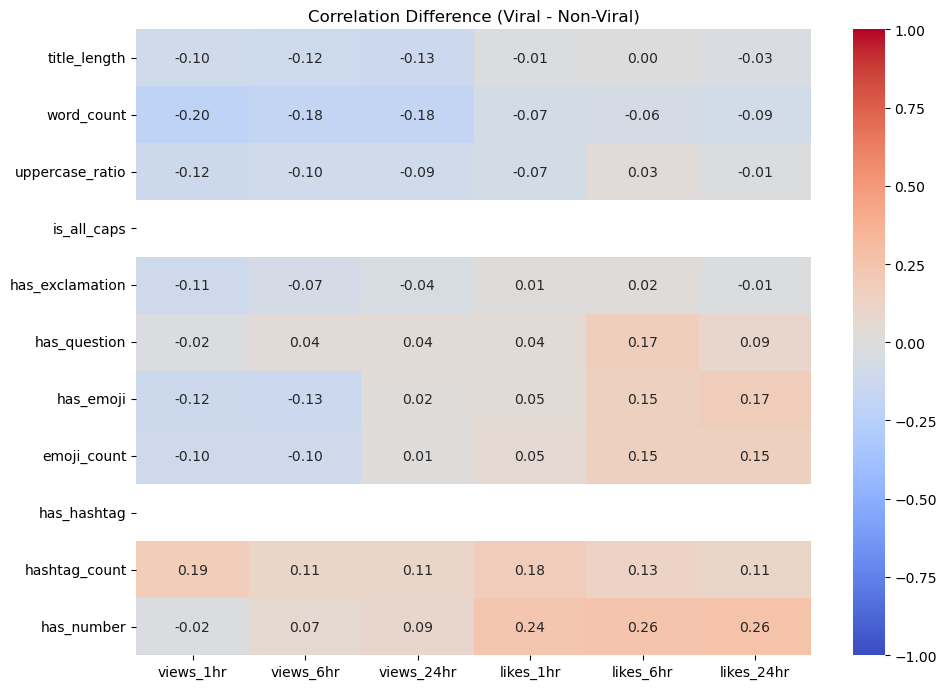

In [19]:
# compare correlation matrices

corr_difference = viral_corr - non_viral_corr

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_difference,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Difference (Viral - Non-Viral)")
plt.tight_layout()
plt.show()


### Identify frequently used words in titles

### Function for word count and frequency

In [20]:
stop_words = set(ENGLISH_STOP_WORDS)

def get_text_word_counts(series, remove_stopwords=True):
    words = []

    for text in series.dropna().astype(str).str.lower():
        tokens = re.findall(r"\b[a-z]+\b", text)

        for word in tokens:
            if len(word) <= 1:
                continue
            if remove_stopwords and word in stop_words:
                continue
            words.append(word)

    counts = Counter(words)
    total = len(words)

    frequencies = {
        word: count / total
        for word, count in counts.items()
    } if total else {}

    return counts, frequencies, total

### Title Analysis

In [21]:
title_analysis = get_text_word_counts(analysis_df["title"])

Most common title words overall

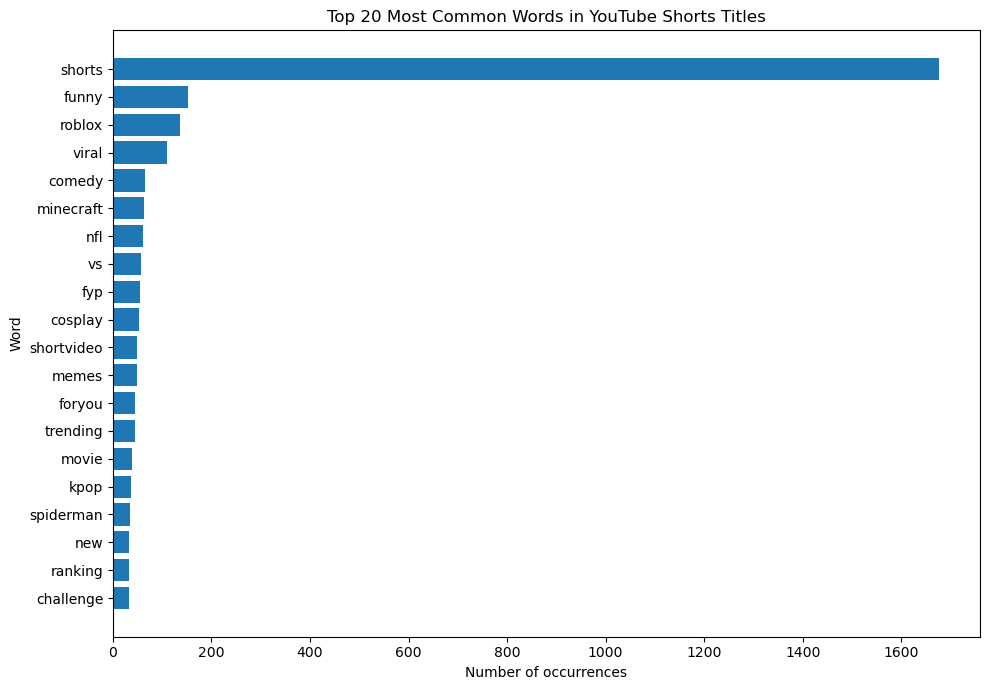

In [22]:
title_top_words = title_analysis[0].most_common(20)
words, counts = zip(*title_top_words)

plt.figure(figsize=(10, 7))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Number of occurrences")
plt.ylabel("Word")
plt.title("Top 20 Most Common Words in YouTube Shorts Titles")
plt.tight_layout()
plt.show()

Comparing relative words in viral and non-viral video titles

In [23]:
def plot_relative_frequencies(
    viral_freq,
    nonviral_freq,
    top_n=20,
    title="Relative Word Frequencies: Viral vs. Non-Viral"
):
    freq_df = pd.DataFrame({
        "Viral": pd.Series(viral_freq),
        "Non-viral": pd.Series(nonviral_freq)
    }).fillna(0)

    freq_df["Difference"] = freq_df["Viral"] - freq_df["Non-viral"]

    top_words = freq_df["Difference"].abs().nlargest(top_n).index
    plot_df = freq_df.loc[top_words].sort_values("Difference")

    ax = plot_df[["Viral", "Non-viral"]].plot(
        kind="barh",
        figsize=(11, max(6, top_n * 0.35)),
        width=0.8
    )

    ax.set_xlabel("Relative frequency")
    ax.set_ylabel("Word")
    ax.set_title(title)
    ax.legend(title="Video group")

    plt.tight_layout()
    plt.show()

    return freq_df.sort_values("Difference", ascending=False)

In [24]:
title_viral_counts, title_viral_freq, title_viral_total = get_text_word_counts(viral_df["title"])
title_nonviral_counts, title_nonviral_freq, title_nonviral_total = get_text_word_counts(non_viral_df["title"])

print("Viral titles:")
print(title_viral_counts.most_common(20))

print("\nNon-viral titles:")
print(title_nonviral_counts.most_common(20))


Viral titles:
[('shorts', 187), ('cosplay', 32), ('roblox', 23), ('funny', 20), ('kpop', 18), ('minecraft', 16), ('spiderman', 16), ('memes', 13), ('viral', 12), ('animation', 9), ('viralvideo', 9), ('vs', 8), ('baby', 8), ('trending', 7), ('comedy', 7), ('spider', 6), ('jj', 6), ('did', 5), ('best', 5), ('laugh', 5)]

Non-viral titles:
[('shorts', 1308), ('funny', 113), ('roblox', 99), ('viral', 88), ('comedy', 55), ('nfl', 53), ('fyp', 46), ('shortvideo', 45), ('minecraft', 43), ('foryou', 42), ('vs', 39), ('memes', 32), ('trending', 32), ('movie', 30), ('new', 29), ('ranking', 28), ('usa', 25), ('gaming', 24), ('challenge', 24), ('man', 23)]


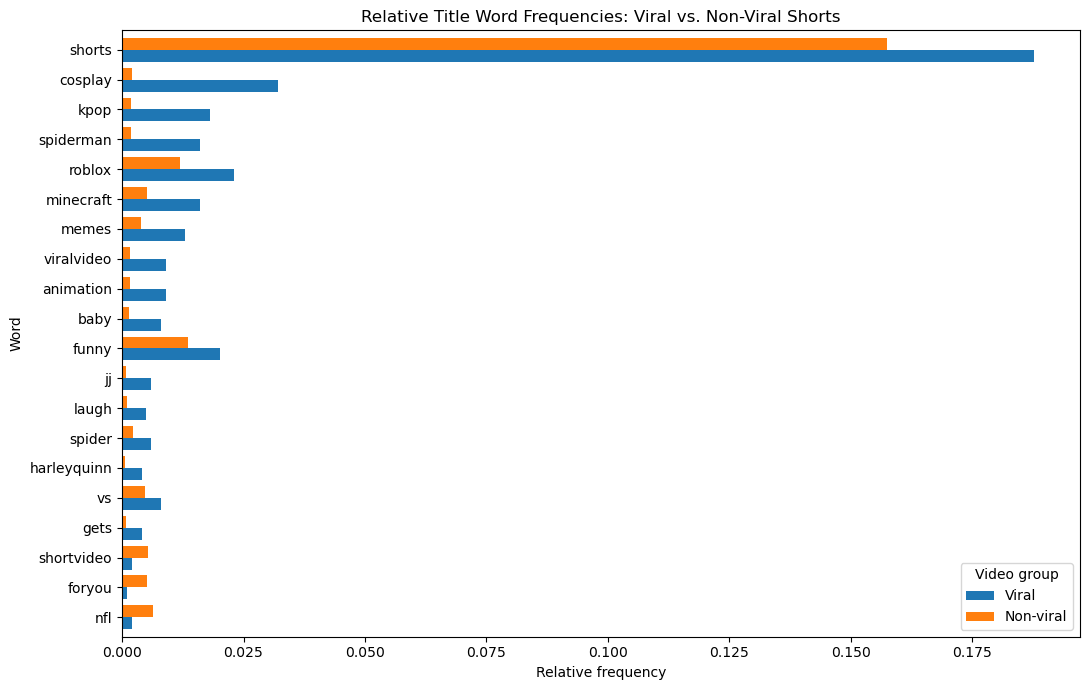

In [55]:
title_freq_df = plot_relative_frequencies(title_viral_freq, title_nonviral_freq,20,"Relative Title Word Frequencies: Viral vs. Non-Viral Shorts")

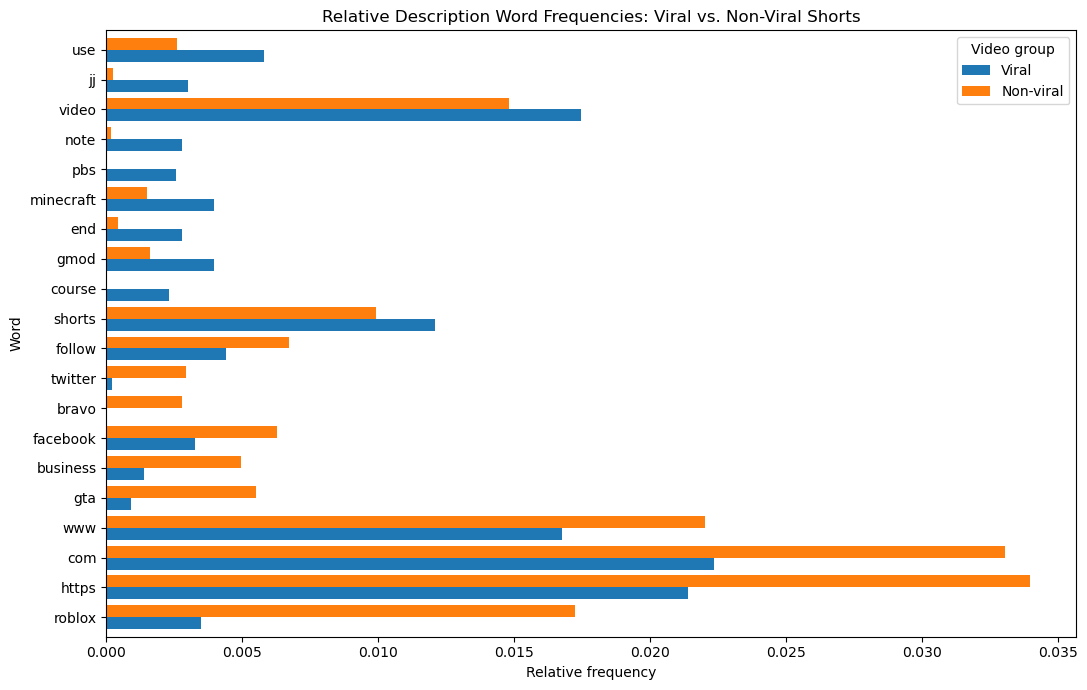

In [56]:
desc_viral_counts, desc_viral_freq, desc_viral_total = get_text_word_counts(viral_df["description"])
desc_nonviral_counts, desc_nonviral_freq, desc_nonviral_total = get_text_word_counts(non_viral_df["description"])

desc = plot_relative_frequencies(desc_viral_freq, desc_nonviral_freq, 20, "Relative Description Word Frequencies: Viral vs. Non-Viral Shorts")


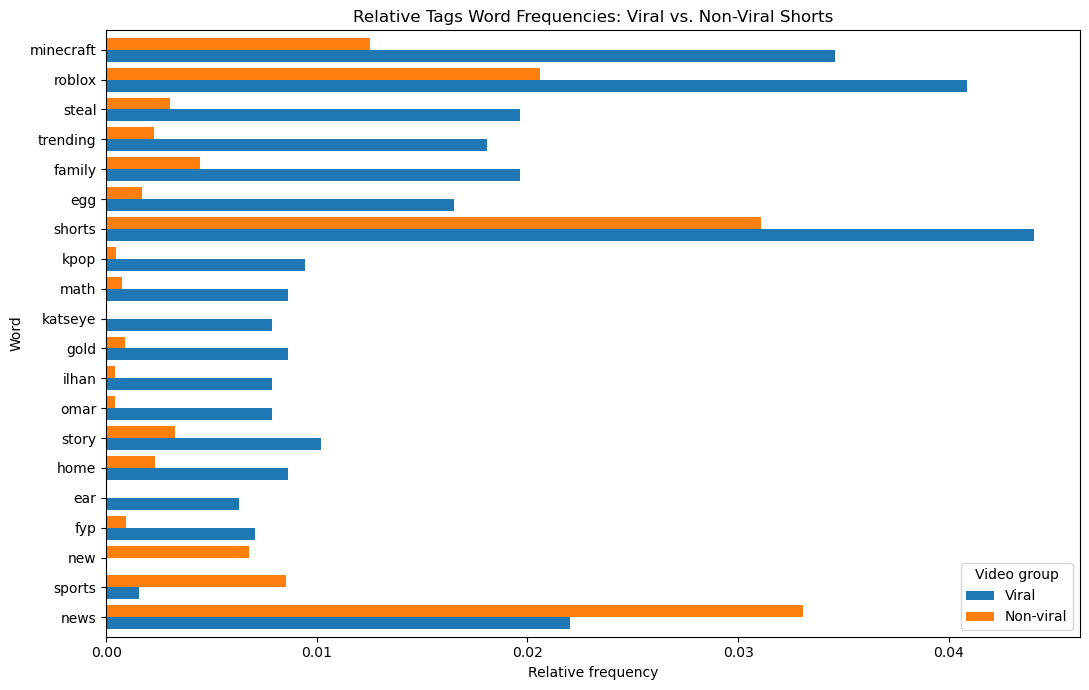

In [57]:
tags_viral_counts, tags_viral_freq, tags_viral_total = get_text_word_counts(viral_df["tags"])
tags_nonviral_counts, tags_nonviral_freq, tags_nonviral_total = get_text_word_counts(non_viral_df["tags"])

tags_freq_df = plot_relative_frequencies(tags_viral_freq, tags_nonviral_freq, 20, "Relative Tags Word Frequencies: Viral vs. Non-Viral Shorts")

### Look at phrases

In [ ]:
def get_phrase_frequencies(series, ngram_range=(2, 3), min_df=2):

    texts = (
        series.fillna("")
        .astype(str)
        .str.lower()
        .str.replace(r"https?://\S+|www\.\S+", " ", regex=True)     # removes URLs
    )

    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        stop_words="english",
        min_df=min_df,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b"
    )

    matrix = vectorizer.fit_transform(texts)

    phrases = vectorizer.get_feature_names_out()
    counts = matrix.sum(axis=0).A1

    phrase_counts = Counter(dict(zip(phrases, counts)))

    # Normalize by total phrase occurrences
    total = sum(phrase_counts.values())
    phrase_freq = {
        phrase: count / total
        for phrase, count in phrase_counts.items()
    } if total else {}

    return phrase_counts, phrase_freq

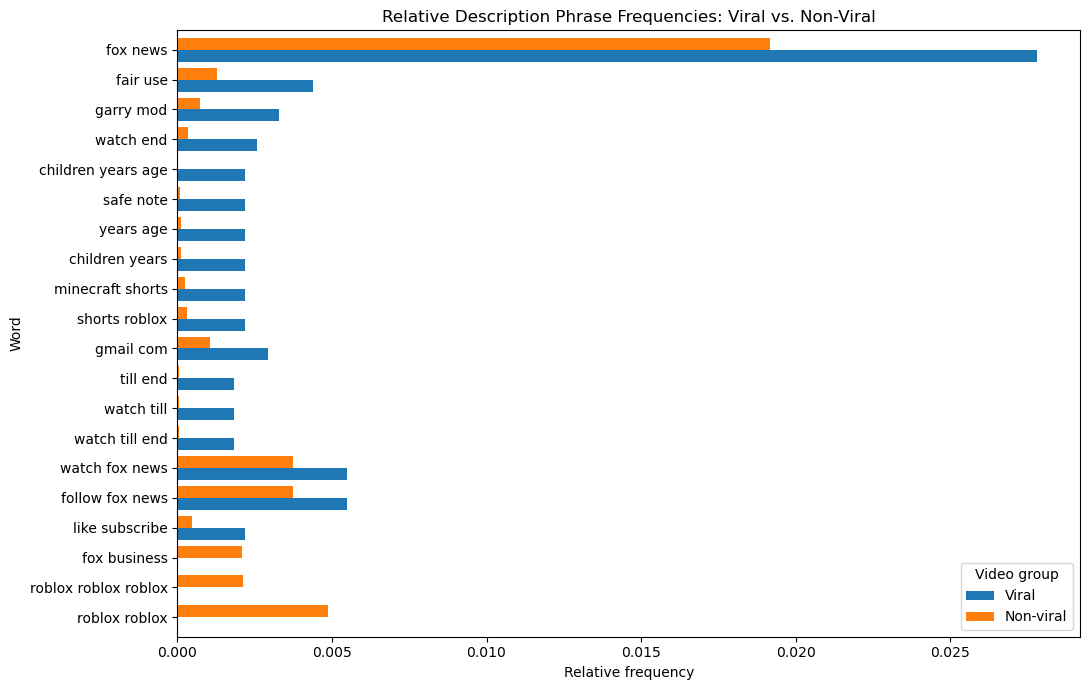

In [54]:
viral_phrase_counts, viral_phrase_freq = get_phrase_frequencies(
    viral_df["description"]
)

nonviral_phrase_counts, nonviral_phrase_freq = get_phrase_frequencies(
    non_viral_df["description"]
)

descrption_phrase_df = plot_relative_frequencies(viral_phrase_freq, nonviral_phrase_freq, 20, "Relative Description Phrase Frequencies: Viral vs. Non-Viral")

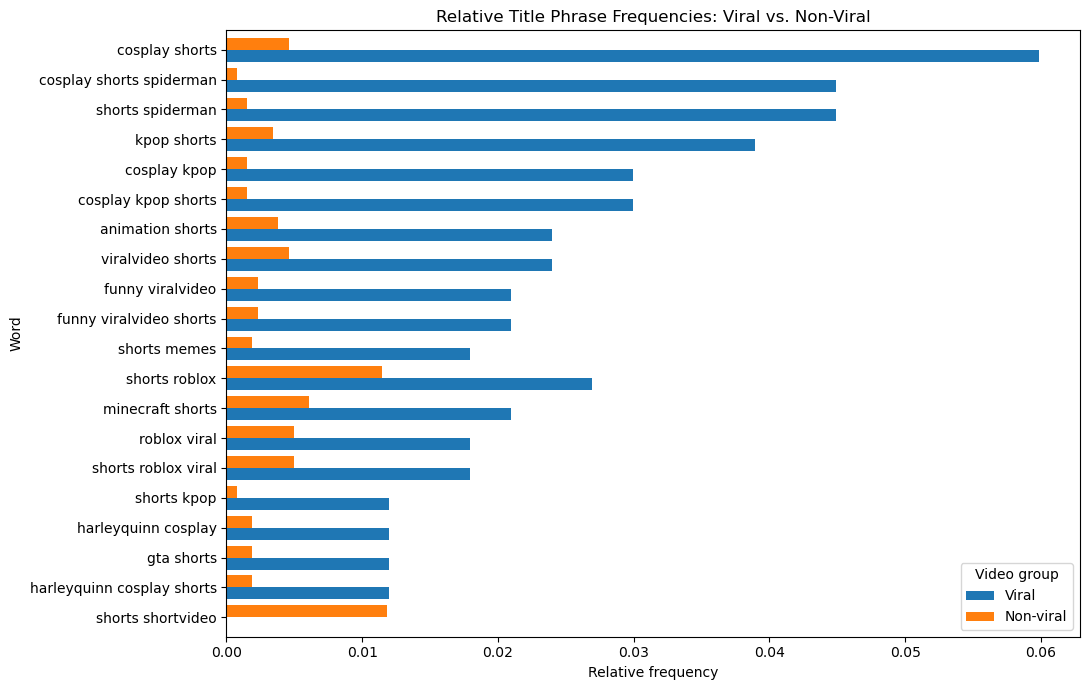

In [52]:
viral_phrase_counts, viral_phrase_freq = get_phrase_frequencies(
    viral_df["title"]
)

nonviral_phrase_counts, nonviral_phrase_freq = get_phrase_frequencies(
    non_viral_df["title"]
)

title_phrase_df = plot_relative_frequencies(viral_phrase_freq, nonviral_phrase_freq, 20, "Relative Title Phrase Frequencies: Viral vs. Non-Viral")

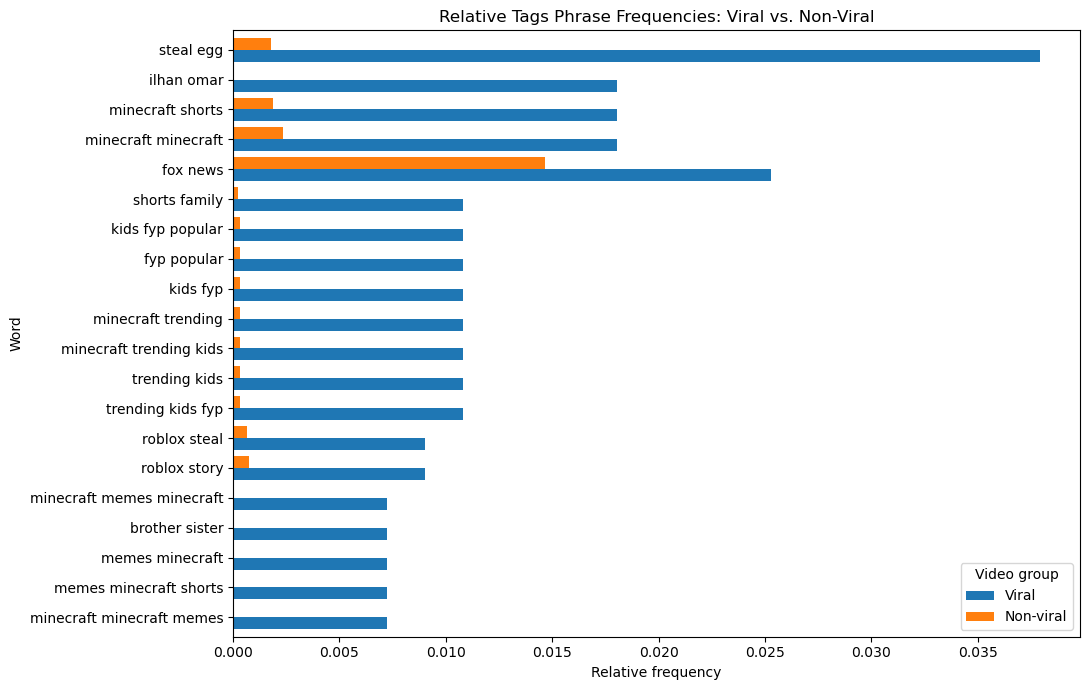

In [53]:
viral_phrase_counts, viral_phrase_freq = get_phrase_frequencies(
    viral_df["tags"]
)

nonviral_phrase_counts, nonviral_phrase_freq = get_phrase_frequencies(
    non_viral_df["tags"]
)

tags_phrase_df = plot_relative_frequencies(viral_phrase_freq, nonviral_phrase_freq, 20, "Relative Tags Phrase Frequencies: Viral vs. Non-Viral")